# 🫀 ACDC — Cardiac segmentation with U-Net

Ce notebook entraîne un **U-Net 2D** pour segmenter, coupe par coupe, les trois structures cardiaques du dataset ACDC :
VD (ventricule droit), myocarde et VG (ventricule gauche), sur fond de label 0.

**Prérequis**
- Le notebook de prétraitement (`02_preprocessing_acdc_colab`) a été exécuté, et `preprocessed/metadata.csv` existe sur Drive.
- Activez le GPU : **Exécution → Modifier le type d'exécution → GPU**.

**Plan**
1. Configuration et chargement des données prétraitées
2. Découpage train / validation / test (déjà fait dans le prétraitement)
3. Dataset PyTorch
4. Architecture U-Net
5. Fonction de perte et métriques (Dice, IoU)
6. Entraînement
7. Courbes de loss et de métriques
8. Évaluation sur validation et test
9. Visualisation des prédictions

> 📝 Par souci de simplicité, aucune augmentation de données n'est utilisée. C'est une piste d'amélioration naturelle si les performances de validation sont limitées.

## 1. Configuration and imports

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

if not os.path.exists("/content/drive/MyDrive/segmentation_cardiaque"):
    from google.colab import drive
    drive.mount("/content/drive")

DATA_ROOT = Path("/content/drive/MyDrive/segmentation_cardiaque")
META_PATH = DATA_ROOT / "preprocessed" / "metadata.csv"
RUN_DIR = DATA_ROOT / "unet_runs"
RUN_DIR.mkdir(parents=True, exist_ok=True)

NUM_CLASSES = 4
CLASS_NAMES = ["Fond", "VD", "Myocarde", "VG"]
BASE_CHANNELS = 32
BATCH_SIZE = 8
EPOCHS = 80
PATIENCE = 15
MIN_LR = 1e-5
LEARNING_RATE = 1e-3
SEED = 42

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", DEVICE)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

Mounted at /content/drive
Device : cuda


## 2. Loading the data

Chaque volume prétraité contient 10 coupes environ. On transforme les volumes en une **liste de coupes 2D** :
le modèle apprend à segmenter une image à la fois.

Pour l'entraînement et l'évaluation, on ne garde que les coupes qui contiennent du cœur. Les coupes de base ou d'apex sans cœur (environ 5 %) sont exclues, car elles ne sont pas informatives pour la segmentation.

In [2]:
meta = pd.read_csv(META_PATH)
print(meta["subset"].value_counts().to_string())

def load_split(subset):
    """Charge toutes les coupes contenant du cœur pour un sous-ensemble (train, val ou test)."""
    images, masks, patients = [], [], []
    for _, row in meta[meta["subset"] == subset].iterrows():
        data = np.load(DATA_ROOT / row["npz"])
        img = np.transpose(data["image"], (2, 0, 1)).astype(np.float32)
        mask = np.transpose(data["mask"], (2, 0, 1)).astype(np.uint8)
        keep = (mask > 0).any(axis=(1, 2))
        images.append(img[keep])
        masks.append(mask[keep])
        patients += [row["patient"]] * int(keep.sum())
    return np.concatenate(images), np.concatenate(masks), np.array(patients)

X_train, y_train, _ = load_split("train")
X_val, y_val, _ = load_split("val")
X_test, y_test, _ = load_split("test")

print(f"Train : {X_train.shape}  | Validation : {X_val.shape}  | Test : {X_test.shape}")

subset
train    160
test     100
val       40
Train : (1455, 256, 256)  | Validation : (386, 256, 256)  | Test : (1001, 256, 256)


## 3. PyTorch dataset

Un `Dataset` présente les données au modèle sous la forme `(canal, hauteur, largeur)`.
Pour la segmentation, le masque est un entier par pixel, et non un vecteur.

In [3]:
class SliceDataset(Dataset):
    def __init__(self, images, masks):
        self.images = np.ascontiguousarray(images)
        self.masks = np.ascontiguousarray(masks)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        x = torch.from_numpy(self.images[idx]).unsqueeze(0)
        y = torch.from_numpy(self.masks[idx].astype(np.int64))
        return x, y

train_loader = DataLoader(SliceDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(SliceDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(SliceDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

## 4. U-Net architecture

Le U-Net a deux parties :
- un **encodeur** (contraction) qui réduit la résolution et extrait des caractéristiques de plus en plus abstraites ;
- un **décodeur** (expansion) qui remonte à la résolution d'origine.

Les **connexions de saut** (*skip connections*) recopient les caractéristiques de l'encodeur vers le décodeur. Elles permettent de conserver les détails fins, indispensables pour délimiter précisément le myocarde.

In [4]:
class DoubleConv(nn.Module):
    """Deux convolutions 3x3 suivies de BatchNorm et ReLU."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_ch=1, n_classes=NUM_CLASSES, base=BASE_CHANNELS):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]

        self.enc1 = DoubleConv(in_ch, c[0])
        self.enc2 = DoubleConv(c[0], c[1])
        self.enc3 = DoubleConv(c[1], c[2])
        self.enc4 = DoubleConv(c[2], c[3])
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(c[3], c[4])

        self.up4 = nn.ConvTranspose2d(c[4], c[3], kernel_size=2, stride=2)
        self.dec4 = DoubleConv(c[4], c[3])
        self.up3 = nn.ConvTranspose2d(c[3], c[2], kernel_size=2, stride=2)
        self.dec3 = DoubleConv(c[3], c[2])
        self.up2 = nn.ConvTranspose2d(c[2], c[1], kernel_size=2, stride=2)
        self.dec2 = DoubleConv(c[2], c[1])
        self.up1 = nn.ConvTranspose2d(c[1], c[0], kernel_size=2, stride=2)
        self.dec1 = DoubleConv(c[1], c[0])

        self.out = nn.Conv2d(c[0], n_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)


model = UNet().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"Nombre de paramètres : {n_params / 1e6:.2f} M")

with torch.no_grad():
    dummy = torch.zeros(2, 1, 256, 256, device=DEVICE)
    print("Forme de la sortie :", tuple(model(dummy).shape))

Nombre de paramètres : 7.76 M
Forme de la sortie : (2, 4, 256, 256)


## 5. Loss and metrics

**Perte** : on combine deux termes.
- La **cross-entropy** traite chaque pixel comme une classification.
- La **perte Dice** compense le fort déséquilibre entre fond et cœur, en mesurant directement le recouvrement entre prédiction et masque.

**Métriques** (calculées sur les classes cardiaques, sans le fond) :
- **Dice** = 2 × |P ∩ G| / (|P| + |G|) : entre 0 et 1, plus c'est haut, mieux c'est.
- **IoU** (Jaccard) = |P ∩ G| / |P ∪ G| : toujours plus sévère que le Dice.

Les scores sont calculés **sur l'ensemble du jeu de données**, en cumulant les intersections et les surfaces de chaque classe.

In [5]:
def dice_loss(logits, target, eps=1e-6):
    probs = torch.softmax(logits, dim=1)
    onehot = F.one_hot(target, NUM_CLASSES).permute(0, 3, 1, 2).float()
    dims = (0, 2, 3)
    intersection = (probs * onehot).sum(dims)
    union = probs.sum(dims) + onehot.sum(dims)
    dice = (2 * intersection + eps) / (union + eps)
    return 1 - dice[1:].mean()


ce_loss = nn.CrossEntropyLoss()

def criterion(logits, target):
    return ce_loss(logits, target) + dice_loss(logits, target)


class SegMeter:
    """Accumule les intersections et surfaces par classe pour calculer Dice et IoU."""
    def __init__(self):
        self.inter = np.zeros(NUM_CLASSES)
        self.pred_sum = np.zeros(NUM_CLASSES)
        self.true_sum = np.zeros(NUM_CLASSES)

    def update(self, pred, target):
        for c in range(NUM_CLASSES):
            p, t = pred == c, target == c
            self.inter[c] += np.logical_and(p, t).sum()
            self.pred_sum[c] += p.sum()
            self.true_sum[c] += t.sum()

    def scores(self, eps=1e-7):
        dice = 2 * self.inter / (self.pred_sum + self.true_sum + eps)
        union = self.pred_sum + self.true_sum - self.inter
        iou = self.inter / (union + eps)
        return dice, iou

def report(meter, title):
    dice, iou = meter.scores()
    df = pd.DataFrame({"Classe": CLASS_NAMES[1:], "Dice": dice[1:], "IoU": iou[1:]})
    print(f"--- {title} ---")
    print(df.round(4).to_string(index=False))
    print(f"Moyenne (classes cardiaques) : Dice = {dice[1:].mean():.4f} | IoU = {iou[1:].mean():.4f}\n")
    return dice[1:].mean(), iou[1:].mean()

## 6. Training

À chaque époque :
- on entraîne sur le jeu d'entraînement ;
- on évalue sur le jeu de validation ;
- on **conserve le meilleur modèle** (meilleur Dice moyen de validation).

Le jeu de test n'est pas utilisé ici : il ne sert qu'à l'évaluation finale.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=MIN_LR)
best_path = RUN_DIR / "best_unet.pt"

def run_epoch(loader, train=False):
    model.train(train)
    total_loss, n_samples = 0.0, 0
    meter = SegMeter()
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(x)
            n_samples += len(x)
            meter.update(logits.argmax(dim=1).cpu().numpy(), y.cpu().numpy())
    dice_mean = meter.scores()[0][1:].mean()
    return total_loss / n_samples, dice_mean

history = {"train_loss": [], "val_loss": [], "train_dice": [], "val_dice": [], "lr": []}
best_dice, bad_epochs = -1.0, 0

for epoch in range(1, EPOCHS + 1):
    current_lr = optimizer.param_groups[0]["lr"]
    tr_loss, tr_dice = run_epoch(train_loader, train=True)
    va_loss, va_dice = run_epoch(val_loader, train=False)
    scheduler.step()

    for k, v in zip(history, (tr_loss, va_loss, tr_dice, va_dice, current_lr)):
        history[k].append(v)

    if va_dice > best_dice:
        best_dice, bad_epochs = va_dice, 0
        torch.save(model.state_dict(), best_path)
        marker = "  ← meilleur modèle"
    else:
        bad_epochs += 1
        marker = ""
    print(f"Époque {epoch:02d}/{EPOCHS} | lr {current_lr:.2e} | loss train {tr_loss:.4f} val {va_loss:.4f} "
          f"| Dice train {tr_dice:.4f} val {va_dice:.4f}{marker}")

    if bad_epochs >= PATIENCE:
        print(f"\nArrêt anticipé : pas d'amélioration depuis {PATIENCE} époques.")
        break

print(f"\nMeilleur Dice de validation (2D) : {best_dice:.4f}")

Époque 01/80 | lr 1.00e-03 | loss train 0.9171 val 0.5560 | Dice train 0.4796 val 0.6572  ← meilleur modèle
Époque 02/80 | lr 1.00e-03 | loss train 0.2725 val 0.2864 | Dice train 0.8106 val 0.8085  ← meilleur modèle
Époque 03/80 | lr 9.98e-04 | loss train 0.1844 val 0.2482 | Dice train 0.8648 val 0.8257  ← meilleur modèle
Époque 04/80 | lr 9.97e-04 | loss train 0.1658 val 0.1876 | Dice train 0.8755 val 0.8709  ← meilleur modèle
Époque 05/80 | lr 9.94e-04 | loss train 0.1478 val 0.2015 | Dice train 0.8887 val 0.8634
Époque 06/80 | lr 9.90e-04 | loss train 0.1332 val 0.1467 | Dice train 0.8986 val 0.8995  ← meilleur modèle
Époque 07/80 | lr 9.86e-04 | loss train 0.1202 val 0.1844 | Dice train 0.9083 val 0.8718
Époque 08/80 | lr 9.81e-04 | loss train 0.1224 val 0.1633 | Dice train 0.9066 val 0.8881
Époque 09/80 | lr 9.76e-04 | loss train 0.1166 val 0.1485 | Dice train 0.9109 val 0.8956
Époque 10/80 | lr 9.69e-04 | loss train 0.1073 val 0.1413 | Dice train 0.9173 val 0.9016  ← meilleur mod

## 7. Learning curves

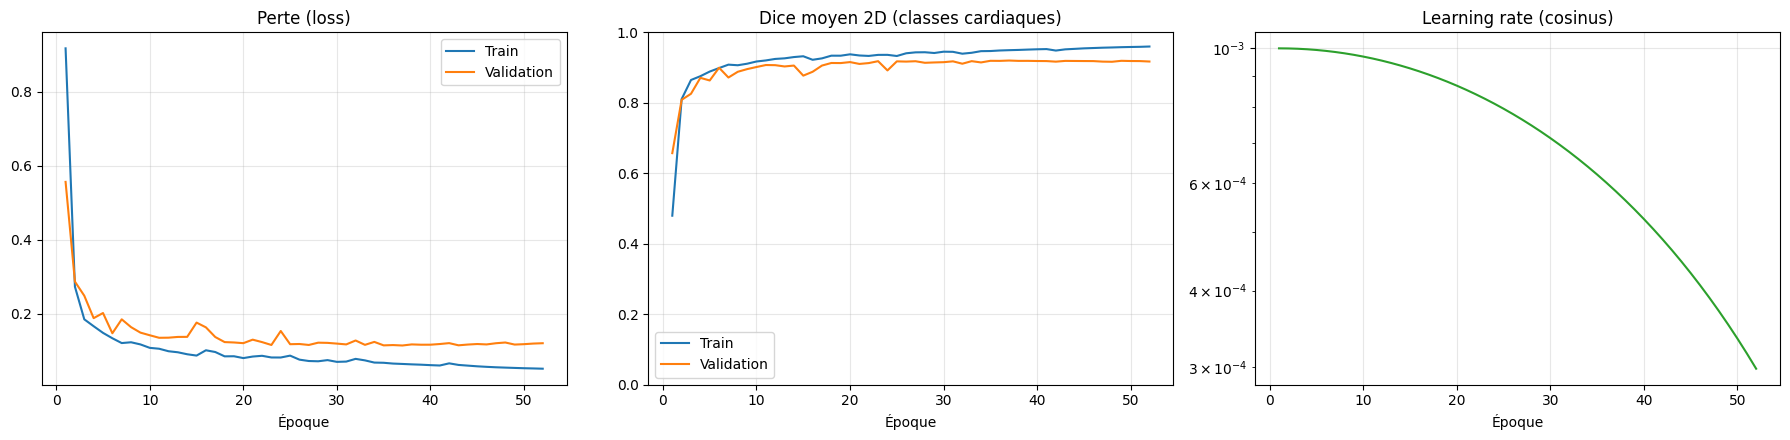

In [7]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].plot(epochs, history["train_loss"], label="Train")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set_title("Perte (loss)")
axes[0].set_xlabel("Époque")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train_dice"], label="Train")
axes[1].plot(epochs, history["val_dice"], label="Validation")
axes[1].set_title("Dice moyen 2D (classes cardiaques)")
axes[1].set_xlabel("Époque")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(epochs, history["lr"], color="tab:green")
axes[2].set_title("Learning rate (cosinus)")
axes[2].set_xlabel("Époque")
axes[2].set_yscale("log")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Comment lire ces courbes :**
- Si la loss de validation remonte alors que celle d'entraînement baisse, le modèle **sur-apprend** : il mémorise les patients d'entraînement.
- Si les deux courbes restent hautes, le modèle **sous-apprend** : il faut plus d'époques, un modèle plus grand ou de meilleures données.

## 8. Final evaluation

On recharge le **meilleur modèle** sauvegardé et on calcule Dice et IoU par classe, sur la validation puis sur le test.

In [8]:
model.load_state_dict(torch.load(best_path, map_location=DEVICE))
model.eval()

def evaluate(loader):
    meter = SegMeter()
    with torch.no_grad():
        for x, y in loader:
            pred = model(x.to(DEVICE)).argmax(dim=1).cpu().numpy()
            meter.update(pred, y.numpy())
    return meter

val_meter = evaluate(val_loader)
test_meter = evaluate(test_loader)

val_dice, val_iou = report(val_meter, "Validation 2D (coupes)")
test_dice, test_iou = report(test_meter, "Test 2D (coupes)")

results = pd.DataFrame({
    "split": ["validation", "test"],
    "dice_moyen": [val_dice, test_dice],
    "iou_moyen": [val_iou, test_iou],
})
results.to_csv(RUN_DIR / "results.csv", index=False)
print("Résultats sauvegardés dans", RUN_DIR / "results.csv")

--- Validation 2D (coupes) ---
  Classe   Dice    IoU
      VD 0.9098 0.8346
Myocarde 0.8937 0.8078
      VG 0.9564 0.9165
Moyenne (classes cardiaques) : Dice = 0.9200 | IoU = 0.8529

--- Test 2D (coupes) ---
  Classe   Dice    IoU
      VD 0.9173 0.8472
Myocarde 0.8926 0.8060
      VG 0.9574 0.9183
Moyenne (classes cardiaques) : Dice = 0.9224 | IoU = 0.8571

Résultats sauvegardés dans /content/drive/MyDrive/segmentation_cardiaque/unet_runs/results.csv


## 9. Per-patient 3D evaluation

Les métriques précédentes sont calculées **coupe par coupe**, sur les coupes contenant du cœur.
Pour une évaluation plus stricte et comparable à la littérature, on segmente **chaque volume entier** (toutes ses coupes, y compris les coupes sans cœur), puis on calcule le Dice et l'IoU **en 3D** pour chaque patient, à la phase ED et à la phase ES.

In [9]:
def predict_volume(img_hwz):
    """Segmente un volume complet (H, W, Z) et renvoie le masque prédit (H, W, Z)."""
    x = torch.from_numpy(np.transpose(img_hwz, (2, 0, 1)).astype(np.float32)).unsqueeze(1)
    preds = []
    with torch.no_grad():
        for i in range(0, len(x), BATCH_SIZE):
            logits = model(x[i:i + BATCH_SIZE].to(DEVICE))
            preds.append(logits.argmax(dim=1).cpu().numpy())
    return np.concatenate(preds).transpose(1, 2, 0).astype(np.uint8)

def evaluate_volumes(subset):
    """Dice et IoU 3D par patient, par phase et par classe."""
    model.eval()
    rows = []
    for _, r in meta[meta["subset"] == subset].iterrows():
        data = np.load(DATA_ROOT / r["npz"])
        pred = predict_volume(data["image"].astype(np.float32))
        meter = SegMeter()
        meter.update(pred, data["mask"])
        dice, iou = meter.scores()
        for c in range(1, NUM_CLASSES):
            rows.append(dict(subset=subset, patient=r["patient"], phase=r["phase"],
                             group=r["group"], classe=CLASS_NAMES[c], dice=dice[c], iou=iou[c]))
    return pd.DataFrame(rows)

df3d_val = evaluate_volumes("val")
df3d_test = evaluate_volumes("test")
df3d = pd.concat([df3d_val, df3d_test])
df3d.to_csv(RUN_DIR / "dice_3d_par_patient.csv", index=False)
print("Volumes évalués (val) :", df3d_val[["patient", "phase"]].drop_duplicates().shape[0],
      "| (test) :", df3d_test[["patient", "phase"]].drop_duplicates().shape[0])

Volumes évalués (val) : 40 | (test) : 100


=== Validation : Dice 3D ===
            mean     std
classe                  
VD        0.8802  0.0796
Myocarde  0.8802  0.0332
VG        0.9286  0.0604
Moyenne des 3 classes : 0.8963

Par groupe clinique (moyenne des 3 classes) :
         mean     std  count
group                       
DCM    0.9217  0.0430     24
HCM    0.8944  0.0589     24
MINF   0.8893  0.0627     24
NOR    0.9025  0.0645     24
RV     0.8738  0.0827     24 

=== Test : Dice 3D ===
            mean     std
classe                  
VD        0.8957  0.0964
Myocarde  0.8812  0.0293
VG        0.9109  0.0886
Moyenne des 3 classes : 0.8959

Par groupe clinique (moyenne des 3 classes) :
         mean     std  count
group                       
DCM    0.9145  0.0468     60
HCM    0.8753  0.0950     60
MINF   0.8974  0.1082     60
NOR    0.8882  0.0692     60
RV     0.9043  0.0484     60 



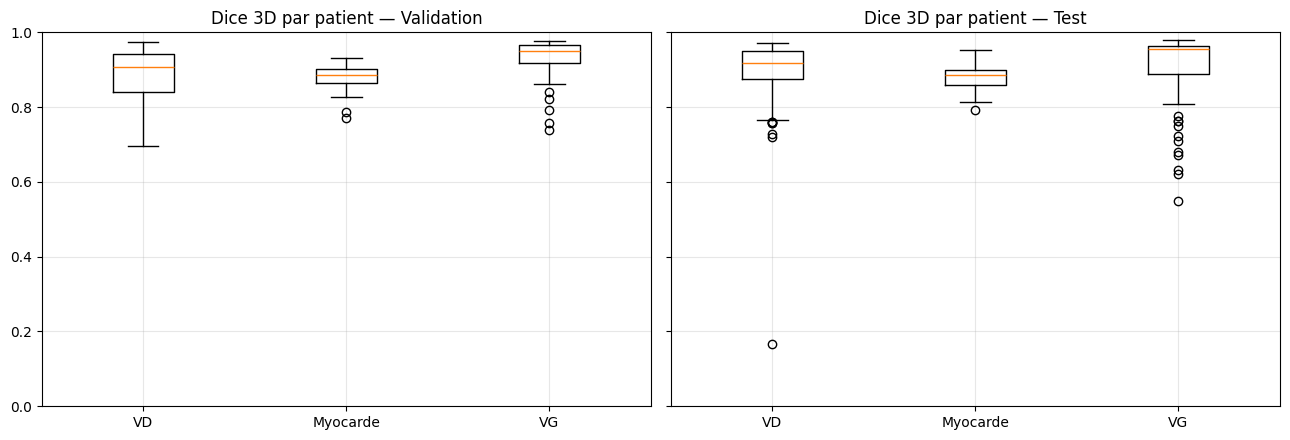

In [11]:
def summarize_3d(df, title):
    print(f"=== {title} : Dice 3D ===")
    per_class = df.groupby("classe")["dice"].agg(["mean", "std"]).reindex(CLASS_NAMES[1:])
    print(per_class.round(4).to_string())
    print(f"Moyenne des 3 classes : {per_class['mean'].mean():.4f}\n")

    print("Par groupe clinique (moyenne des 3 classes) :")
    by_group = df.groupby("group")["dice"].agg(["mean", "std", "count"])
    print(by_group.round(4).to_string(), "\n")

summarize_3d(df3d_val, "Validation")
summarize_3d(df3d_test, "Test")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (df, name) in zip(axes, [(df3d_val, "Validation"), (df3d_test, "Test")]):
    data = [df[df["classe"] == c]["dice"].values for c in CLASS_NAMES[1:]]
    ax.boxplot(data, tick_labels=CLASS_NAMES[1:])
    ax.set_title(f"Dice 3D par patient — {name}")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Prediction visualisation

On compare, pour quelques coupes du jeu de test, l'IRM, le masque réel et la prédiction du modèle.
Le Dice affiché dans le titre est calculé sur la coupe elle-même.

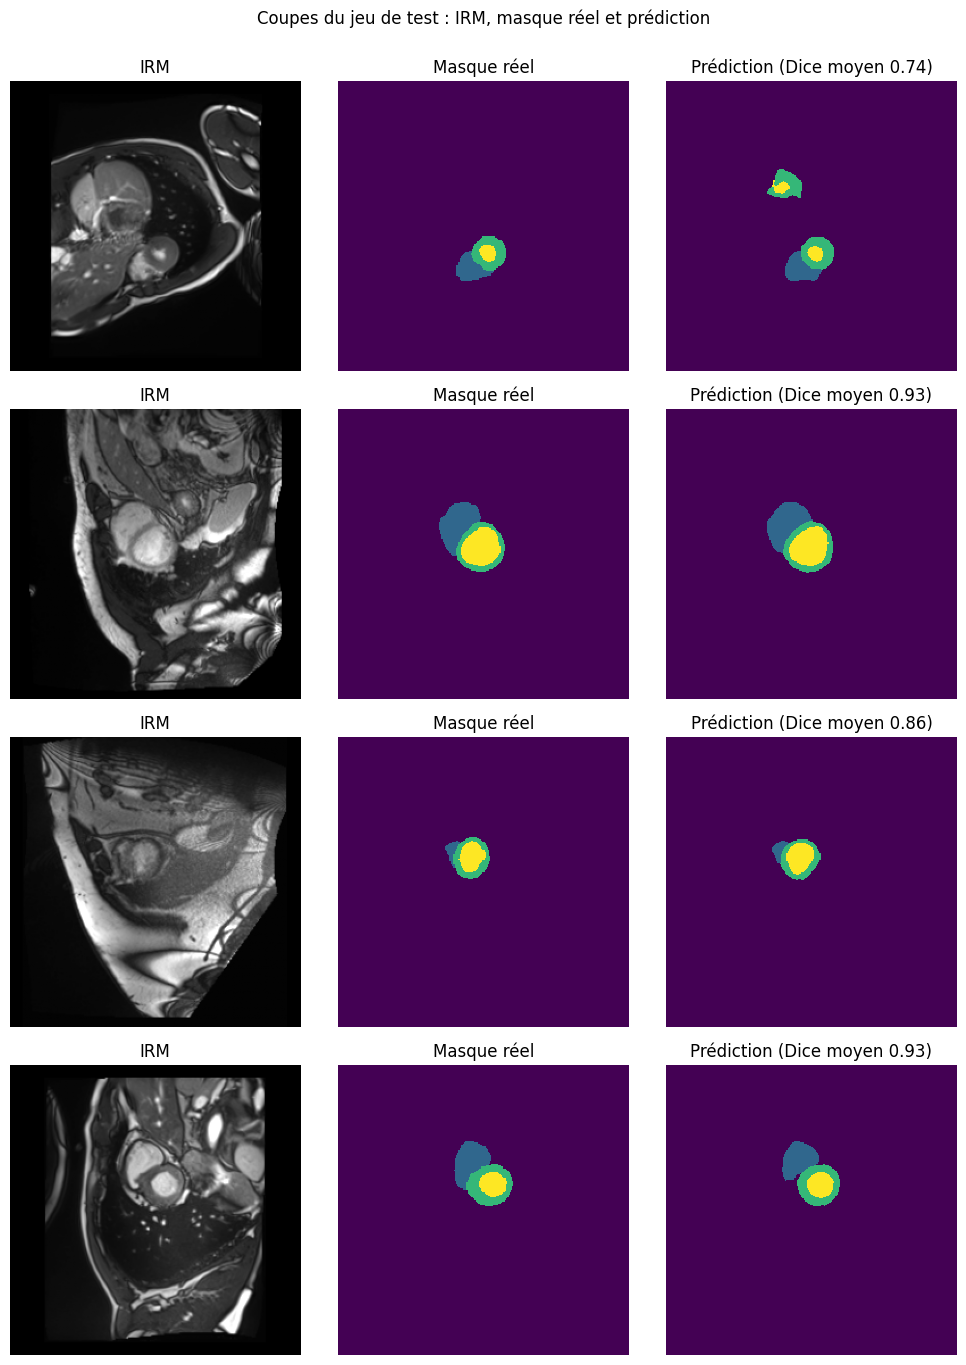

In [12]:
def slice_dice(pred, target, c):
    p, t = pred == c, target == c
    denom = p.sum() + t.sum()
    return 2 * np.logical_and(p, t).sum() / denom if denom > 0 else np.nan

def show_predictions(images, masks, n=4, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(images), size=n, replace=False)

    model.eval()
    with torch.no_grad():
        preds = model(torch.from_numpy(images[idx]).unsqueeze(1).to(DEVICE)).argmax(dim=1).cpu().numpy()

    fig, axes = plt.subplots(n, 3, figsize=(10, 3.4 * n))
    for row, i, pred in zip(axes, idx, preds):
        img = images[i]
        gt = masks[i]
        dices = [slice_dice(pred, gt, c) for c in range(1, NUM_CLASSES)]
        mean_dice = np.nanmean(dices)

        row[0].imshow(np.rot90(img), cmap="gray")
        row[0].set_title("IRM")
        row[1].imshow(np.rot90(gt), cmap="viridis", vmin=0, vmax=NUM_CLASSES - 1, interpolation="nearest")
        row[1].set_title("Masque réel")
        row[2].imshow(np.rot90(pred), cmap="viridis", vmin=0, vmax=NUM_CLASSES - 1, interpolation="nearest")
        row[2].set_title(f"Prédiction (Dice moyen {mean_dice:.2f})")
        for ax in row:
            ax.axis("off")

    fig.suptitle("Coupes du jeu de test : IRM, masque réel et prédiction", y=1.0)
    plt.tight_layout()
    plt.show()

show_predictions(X_test, y_test, n=4)

## 11. Going further

- **Augmentation de données** (rotations légères, zoom, bruit) : la piste la plus efficace pour gagner encore en Dice.
- **Post-traitement** : retirer les petites composantes isolées dans les prédictions 3D.
- **Modèle 3D ou coupes voisines** pour exploiter la continuité entre coupes.